# Analysis of Retail Sales Data

The Retail Sales dataset contains transactional sales records that represent customer purchasing behavior in a retail environment. The dataset includes information about each transaction such as the transaction identifier, customer details, product categories, and sales amounts. This data can be used to analyze purchasing patterns, customer information, and sales performance.

The dataset provides an opportunity to explore relationships between different variables, such as how customer characteristics affect purchasing behavior, which product categories generate the highest sales, and how prices and quantities influence total sales revenue. Additionally, the dataset can be leveraged to gain insights into customer behavior and support data-driven decision-making in retail business management and marketing strategies.

Description of the variables used in the data:

	•	transaction_id: A unique identifier for each sales transaction in the dataset.
	•	date: The date on which the transaction occurred.
	•	customer_id: A unique identifier assigned to each customer.
	•	gender: The gender of the customer.
	•	age: The age of the customer.
	•	product_category: The category of the purchased product.
	•	quantity: The number of units purchased in a transaction.
	•	price_per_unit: The price of a single unit of the product.
	•	total_amount: The total amount of the transaction, calculated as the product of quantity and price per unit.

# Section 1: Data Loading & Inspection

**Introduction**

> في هذا القسم تم تحميل مجموعة البيانات وفحصها مبدئيًا لفهم بنيتها العامة، نوع الأعمدة، حجم البيانات، وخصائصها الأساسية قبل البدء بعمليات التنظيف والتحليل.

⸻

**Explanation** **Required**
**What** **does** **each** **function** **show** **?**

> read_csv() : تحميل ملف البيانات وتحويله إلى DataFrame.

> head() : عرض أول صفوف من البيانات.

> shape : إظهار عدد الصفوف والأعمدة.

> columns : عرض أسماء الأعمدة.

> info() : إظهار أنواع البيانات وعدد القيم غير الفارغة.

> describe() : إحصاءات وصفية للأعمدة الرقمية.


**Initial** **Observations**
> تحتوي البيانات على 1000 صف.

> تحتوي على 11 عمود.

> يوجد أعمدة رقمية مثل العمر والسعر والإجمالي.

> يوجد أعمدةوصفية مثل الجنس وفئة المنتج.

> البيانات تمثل عمليات بيع بالتجزئة لعملاء مختلفين.


Import Required Libraries

تم استيراد مكتبة Pandas لمعالجة البيانات

 ومكتبة NumPy للعمليات العددية

In [ ]:
import pandas as pd
import numpy as n
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import PCA
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import RFE

# Load dataset
data_retail = pd.read_csv('/content/retail_sales_split_date.csv')

# Display first 100 rows
data_retail.head(5)

#هذا الفحص يساعد على:
#التأكد من نجاح تحميل الملف
#مراجعة تنسيق الأعمدة
#اكتشاف قيم غريبة أو مفقودة مبكرًا

,Transaction ID,Customer ID,Gender,Age,Product Category-20,Quantity-10,Price per Unit-10,Total Amount,Day,Month,Year
0,1,CUST001,Male,34,Beauty,3.0,50.0,150,24,11,2023
1,2,CUST002,Female,26,Clothing,2.0,500.0,1000,27,2,2023
2,3,CUST003,Male,50,Electronics,1.0,30.0,30,13,1,2023
3,4,CUST004,Male,37,Clothing,1.0,500.0,500,21,5,2023
4,5,CUST005,Male,30,Beauty,2.0,50.0,100,6,5,2023


Display Dataset Information

تم استخدام info() لفحص هيكل البيانات


In [ ]:
# Dataset information
data_retail.info()

#Scientific Interpretation
#يوضح:
#عدد الصفوف
#عدد الأعمدة
#أسماء الأعمدة
#نوع كل عمود
#عدد القيم غير الفارغة
#هذا مهم لاكتشاف الأعمدة التي تحتوي على Missing Values أو أنواع خاطئة.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Transaction ID       1000 non-null   int64  
 1   Customer ID          1000 non-null   object 
 2   Gender               1000 non-null   object 
 3   Age                  1000 non-null   int64  
 4   Product Category-20  978 non-null    object 
 5   Quantity-10          985 non-null    float64
 6   Price per Unit-10    985 non-null    float64
 7   Total Amount         1000 non-null   int64  
 8   Day                  1000 non-null   int64  
 9   Month                1000 non-null   int64  
 10  Year                 1000 non-null   int64  
dtypes: float64(2), int64(6), object(3)
memory usage: 86.1+ KB


Statistical Summary

تم استخدام describe() لاستخراج الإحصاءات الوصفية للأعمدة الرقمية


In [ ]:
# Statistical summary
data_retail.describe()

#Scientific Interpretation
#يعرض:
#المتوسط الحسابي Mean
#الانحراف المعياري Std
#أقل قيمة Min
#أكبر قيمة Max
#الربعيات Quartiles

#ويستخدم لفهم توزيع البيانات واكتشاف القيم غير الطبيعية

,Transaction ID,Age,Quantity-10,Price per Unit-10,Total Amount,Day,Month,Year
count,1000.000000,1000.00000,985.000000,985.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514721,179.314721,456.000000,15.310000,6.549000,2023.002000
std,288.819436,13.68143,1.131603,189.729060,559.997632,8.871674,3.452755,0.044699
min,1.000000,18.00000,1.000000,25.000000,25.000000,1.000000,1.000000,2023.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000,7.000000,4.000000,2023.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000,15.000000,6.000000,2023.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000,23.000000,10.000000,2023.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000,31.000000,12.000000,2024.000000


Dataset Shape

تم استخدام shape لمعرفة حجم البيانات

In [ ]:
# Shape
data_retail.shape

#Scientific Interpretation
#الناتج:
#1000 صف
#11 عمود
#وهذا يوضح حجم العينة المستخدمة في التحليل.

(1000, 11)

Display Column Names

تم استخدام columns لمعرفة أسماء المتغيرات المتاحة


In [ ]:
# Columns
data_retail.columns

#Scientific Interpretation
#يساعد ذلك على:
#اختيار الأعمدة المناسبة للتحليل
#تحديد الأعمدة الرقمية والوصفية
#تسهيل كتابة الأكواد اللاحقة

Index(['Transaction ID', 'Customer ID', 'Gender', 'Age', 'Product Category-20',
       'Quantity-10', 'Price per Unit-10', 'Total Amount', 'Day', 'Month',
       'Year'],
      dtype='object')

Final Initial Observations

من الفحص المبدئي يتضح أن البيانات منظمة نسبيًا وتحتوي على متغيرات مناسبة لإجراء:

Data Cleaning

Exploratory Data Analysis

Statistical Aggregation

Visualization

# Section 2: Data Quality Assessment

**Introduction**

يهدف هذا القسم إلى تقييم جودة البيانات من خلال اكتشاف المشكلات مثل القيم المفقودة، التكرارات، القيم غير الصحيحة، وعدم اتساق البيانات، وذلك قبل البدء بعملية التنظيف لضمان صحة التحليل لاحقًا.

⸻

**Explanation** **Required**

List all detected issues

تم اكتشاف المشكلات التالية:

وجود قيم مفقودة (Missing Values)

 عدم وجود صفوف مكررة(Duplicate Rows)

عدم وجود قيم غير متسقة في النصوص (Inconsistent Labels)

عدم وجود قيم غير صحيحة أو غير منطقية (Invalid Values)

عدم وجود أنواع بيانات غير مناسبة لبعض الأعمدة (Incorrect Data Types)


⸻

How each issue was found + Evidence

**Check for missing values in each column**

نفحص هل يوجد قيم مفقودة في كل عمود

isnull().sum(): تحسب عدد القيم الفارغة في كل عمود ,  وجدنا قيمًا مفقودة في فئة المنتج والكمية والسعر، وتحتاج لمعالجة.

In [ ]:

missing_values=data_retail.isnull().sum()
missing_values
#Scientific Explanation
#هذه الدالة تحسب عدد القيم الفارغة في كل عمود، مما يساعد على تحديد الأعمدة التي تحتاج تنظيف

,0
Transaction ID,0
Customer ID,0
Gender,0
Age,0
Product Category-20,22
Quantity-10,15
Price per Unit-10,15
Total Amount,0
Day,0
Month,0


In [ ]:
# Display only columns that contain missing values
# نعرض فقط الأعمدة اللي فيها قيم مفقودة (إن وُجدت)
missing_values = missing_values[missing_values > 0]
missing_values
#Scientific Explanation
#يتم عرض الأعمدة التي تحتوي على قيم مفقودة فقط لتسهيل التركيز على المشاكل الفعلية.


,0
Product Category-20,22
Quantity-10,15
Price per Unit-10,15


In [ ]:
# إجمالي القيم المفقودة في كامل الملف
print("\nTotal missing values in all data:", data_retail.isnull().sum().sum())
#يعطي العدد الإجمالي للقيم المفقودة في كامل البيانات.


Total missing values in all data: 52


####**Duplicate Check**

 وجود صفوف مكررة يعني تكرار نفس عملية البيع أكثر من مرة مما يؤثر على النتائج الإحصائية.

In [ ]:

# 2. فحص التكرارات
print("Number of duplicate rows:", data_retail.duplicated().sum())

# عرض الصفوف المكررة
Duplicates = data_retail[data_retail.duplicated()]
print("Show Duplicates row:", Duplicates.head())
#Scientific Explanation
#عرض الصفوف يساعد في فهم نوع التكرار هل هو كامل أم جزئي
# ولكن هنا مافي اي تكرار ف ماظهر لنا اي صف

Number of duplicate rows: 0
Show Duplicates row: Empty DataFrame
Columns: [Transaction ID, Customer ID, Gender, Age, Product Category-20, Quantity-10, Price per Unit-10, Total Amount, Day, Month, Year]
Index: []


####**Inconsistent Labels (المسميات غير الموحدة)**

تم استخدام unique() لاكتشاف اختلافات الكتابة في القيم النصية

####**Unique**

تحدد لنا العدد الصافي للعامود , ومعلومية حجم التنوع في البيانات , ونتاكد ان العملاء لايتكررون

In [ ]:
#  فحص تضارب الحروف الكبيرة والصغيرة في الجنس والمنتجات
#يساعد في اكتشاف مشاكل مثل اختلاف كتابة Male / male أو Female / female.
print("Unique Gender values:", data_retail['Gender'].unique())
print("Unique Product Category values:", data_retail['Product Category-20'].unique())

Unique Gender values: ['Male' 'Female']
Unique Product Category values: ['Beauty' 'Clothing' 'Electronics' nan]


In [ ]:
# حساب عدد العملاء المختلفين
num_customers = data_retail['Customer ID'].nunique()
print("Number of unique customers:", num_customers)
# توضح لنا ان العملاء جمعيهم 1000 وهو مساوي لعدد الصفوف
# وهذا يوضح لنا ان مافيه اي تكرار بالعميل

Number of unique customers: 1000


##### **4. Invalid Values (القيم غير المنطقية)**

تم فحص القيم غير المنطقية مثل الرموز أو القيم السالبة

In [ ]:
#فحص شامل لكل الأعمدة عن رموز و أخطاء لضمان أن جميع القيم صالحة للتحليل
invalid_symbols = ['#NAME?', '#VALUE!']
full_check = data_retail.isin(invalid_symbols).sum()
# بيطبع  فقط الأعمدة اللي فيها أخطاء
full_check[full_check>0]
# ونلاحظ مافي اي خطا بالداتا

,0


####**Negative Values Check**

In [ ]:
# فحص القيم السالبة أو المستحيلة في الأرقام
negative_check = (data_retail[['Age', 'Quantity-10', 'Price per Unit-10']] < 0).sum()
print("Negative values check:\n", negative_check)
#Scientific Explanation
#يتم التأكد من عدم وجود قيم سالبة في أعمدة لا يمكن أن تكون سالبة مثل العمر أو الكمية.


Negative values check:
 Age                  0
Quantity-10          0
Price per Unit-10    0
dtype: int64


####**Data Types Check**

In [ ]:
# 5. Mixed or Incorrect Data Types (أنواع البيانات)
print("\n--- 5. Data Types Check ---")
print(data_retail.dtypes)
#Scientific Explanation
#يساعد على التأكد من أن كل عمود يحمل النوع المناسب (رقمي، نصي، تاريخ).



--- 5. Data Types Check ---
Transaction ID           int64
Customer ID             object
Gender                  object
Age                      int64
Product Category-20     object
Quantity-10            float64
Price per Unit-10      float64
Total Amount             int64
Day                      int64
Month                    int64
Year                     int64
dtype: object


* ### Heatmap Visualization for Missing Values

  تساعد على رؤية أماكن القيم المفقودة و تعطي صورة بصرية سريعة لمكان الفجوات في البيانات الخطوط الصفراء تعني (فراغ)

  الأرقام تعطي الكمية والرسمة تعطي التوزيع هل الفراغات عشوائية أم متركزة في مكان واحد

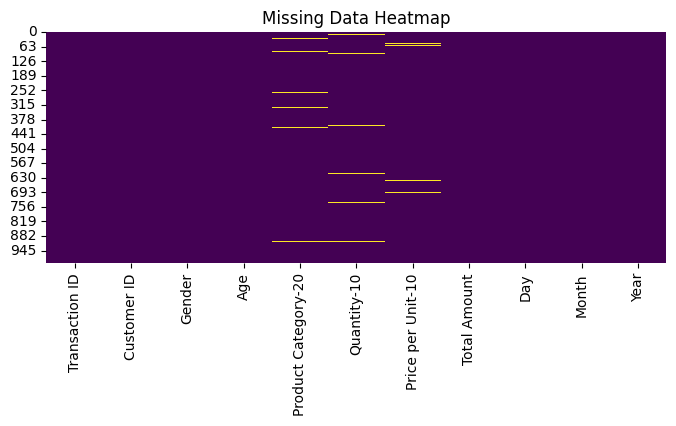

In [ ]:
# 4. رسم خريطة  للقيم المفقودة
plt.figure(figsize=(8,3))
sns.heatmap(data_retail.isnull(), cbar=False, cmap='viridis')
plt.title("Missing Data Heatmap")
plt.show()
#Scientific Explanation
#الخريطة الحرارية تساعد على رؤية أماكن القيم المفقودة بصريًا وتحديد نمطها.

In [ ]:
# إجمالي طول البيانات قبل البدء بالتنظيف)
print("\nFinal status: Length of data before cleaning is:", len(data_retail))


Final status: Length of data before cleaning is: 1000


Final Summary of Issues

من خلال التحليل تم اكتشاف:

وجود Missing Values في بعض الأعمدة

عدم وجودDuplicate Rows

عدم وجود اختلاف في كتابة القيم النصية

عدم وجود رموز غير صحيحة في البيانات

  أنواع البيانات صحيحه

وهذه المشكلات يجب معالجتها قبل الانتقال إلى مرحلة التنظيف والتحليل
(وهي مشكلة القيمه المفقودة فقط)

# Section 3: Data Cleaning & EDA


**A**. **Data** **Cleaning**

**Introduction**

يهدف هذا الجزء إلى تنظيف البيانات من المشاكل المكتشفة في القسم السابق مثل القيم المفقودة، التكرار، الأخطاء في أنواع البيانات، والقيم غير الصحيحة، لضمان أن البيانات جاهزة للتحليل الإحصائي والنمذجة.

⸻

**Explanation** **Required** (**Part** **A**)

**Why** **you** **chose** **each** **method**

> تم استخدام Forward Fill لأن بعض الأعمدة تحتوي على قيم متكررة أو متسلسلة مما يجعل القيمة السابقة تقدير منطقي.

> تم استخدام Dropna لإزالة أي صفوف متبقية تحتوي على قيم مفقودة بعد المعالجة.

> تم استخدام astype() لتصحيح أنواع البيانات.

> تم استخدام التنظيف النصي لتوحيد القيم مثل Gender.

⸻

**Compare** **methods**

Forward Fill: يحافظ على البيانات لكنه قد ينقل قيمة غير دقيقة إذا لم يكن هناك تسلسل منطقي.

Mean/Median (بديل): مناسب للبيانات الرقمية فقط لكنه قد يغير التوزيع.

Dropna: يزيل البيانات بالكامل لكنه يقلل حجم dataset.

⸻

**Justify** **final** **choice**

تم اختيار مزيج Forward Fill + Dropna لأنه:

يحافظ على أكبر عدد من البيانات

يقلل فقد المعلومات

مناسب لطبيعة البيانات (قيم متكررة ووصفية)

#### **Handling Missing Values**

> Add blockquote



Scientific Explanation(Forward Fill)

تم استخدام Forward Fill لتعويض القيم المفقودة باستخدام آخر قيمة صحيحة سابقة، وهو مناسب عندما تكون البيانات شبه متسلسلة أو تحتوي على قيم متكررة


Scientific Explanation(Drop )

تم حذف الصفوف التي لا تزال تحتوي على قيم مفقودة لضمان جودة البيانات النهائية


In [ ]:

# 1. Handle Missing Values


print("Length before handling missing values:\n", len(data_retail))
# تعرض كم طول الداتا مع القيم المفقوده

# يعبي القيمه الي قبلها ( القيمه المفقوده اخذت الي فوقها )
# Forward Fill للقيم المفقودة
data_retail['Product Category-20'].fillna(method='ffill', inplace=True)
data_retail['Quantity-10'].fillna(method='ffill', inplace=True)
data_retail['Price per Unit-10'].fillna(method='ffill', inplace=True)

# حذف أي صفوف متبقية تحتوي على قيم ناقصة
data_retail.dropna(inplace=True)

Length before handling missing values:
 1000


/tmp/ipykernel_4474/2213946296.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data_retail['Product Category-20'].fillna(method='ffill', inplace=True)
/tmp/ipykernel_4474/2213946296.py:9: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data_retail['Product Category-20'].fillna(method='ffill', inplace=True)
/tmp/ipykernel_4474/2213946296.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained a

**Remove Duplicates**

Scientific Explanation

تم حذف التكرارات لتجنب تضخيم النتائج الإحصائية وتحسين دقة التحليل.

In [ ]:
# 2. Remove Duplicates

data_retail.drop_duplicates(inplace=True)
print("Duplicate Rows:", data_retail.duplicated().sum())

# Show the result after removing the duplicated rows
data_retail=data_retail.drop_duplicates()
print("Duplicates after cleaning for the duplicatie row",data_retail.duplicated().sum)
# ال False توضح لنا ان بكل الصفوف مافي اي تكرار

Duplicate Rows: 0
Duplicates after cleaning for the duplicatie row <bound method Series.sum of 0      False
1      False
2      False
3      False
4      False
       ...  
995    False
996    False
997    False
998    False
999    False
Length: 1000, dtype: bool>


#### **Fix Data Types**
( مانحتاجه )

Scientific Explanation

تم تحويل الأعمدة إلى أنواعها الصحيحة لضمان دقة العمليات الحسابية والتحليل الزمني.

In [ ]:
# 3. Fix Data Types
# هنا يحل مشكله التاريخ اذا كان نوعه ليس Datetime
data_retail['Date'] = pd.to_datetime(data_retail['Year'].astype(str) + '-' + data_retail['Month'].astype(str) + '-' + data_retail['Day'].astype(str))
# Quantity و Age → تحويلهم إلى int لتجنب أي أخطاء
data_retail['Quantity-10'] = data_retail['Quantity-10'].fillna(0).astype(int)
data_retail['Age'] = data_retail['Age'].astype(int)
# البيانات خاليه من ذي الاخطاء

####**Standardize Labels**
( مانحتاجه )

Scientific Explanation

 يوحد  كتابة القيم النصية لمنع تكرار نفس الفئة بأكثر من صيغة



In [ ]:

# Fix Additional Data Quality Issues

# Standardize Gender labels
# تحويل كل النصوص إلى أحرف صغيرة لتوحيد الكتابة
data_retail['Gender'] = data_retail['Gender'].str.lower()

# وهنا يخلي بداية كل كلمة تكون كبتل
data_retail['Gender'] = data_retail['Gender'].replace({
    'male': 'Male',
    'female': 'Female'
})
# يحذف الرموز الغريبه ان وجدت ( ماعندنا )
# استخدمناها لذي الاعمده عشلن نضمن انها فريده
# Remove invalid IDs
data_retail = data_retail[
    ~data_retail['Transaction ID'].isin(['#NAME?', '#VALUE!']) &
    ~data_retail['Customer ID'].isin(['#NAME?', '#VALUE!'])
]
# إعطاء خبر بالنتيجة
print(f"Current number of rows: {data_retail.shape[0]}")

# حذف القيم غير الصحيحة التي تنتج عن أخطاء إدخال أو استيراد البيانات.
#ماعندنا اخطاء بالصيغ او القيم غير المنطقيه

Current number of rows: 1000


In [ ]:

# isnull().sum()  التأكد من عدم وجود أي Missing Values بعد التنظيف.
#shape  التحقق من عدد الصفوف والأعمدة بعد حذف الصفوف المكررة والمفقودة.
#dtypes  التأكد من أن كل الأعمدة لديها النوع المناسب (int, float, datetime).

print("\nMissing Values After Cleaning:")
print(data_retail.isnull().sum())

print("\nDataset Shape:")
print(data_retail.shape)

print("\nData Types:")
print(data_retail.dtypes)

print("\nFirst Rows:")
print(data_retail.head())

print("Length of data after cleaning :", len(data_retail))
# يعطي نفس الناتج قبل لان تم تعبيئة البيانات ب forward fillه


Missing Values After Cleaning:
Transaction ID         0
Customer ID            0
Gender                 0
Age                    0
Product Category-20    0
Quantity-10            0
Price per Unit-10      0
Total Amount           0
Day                    0
Month                  0
Year                   0
Date                   0
dtype: int64

Dataset Shape:
(1000, 12)

Data Types:
Transaction ID                  int64
Customer ID                    object
Gender                         object
Age                             int64
Product Category-20            object
Quantity-10                     int64
Price per Unit-10             float64
Total Amount                    int64
Day                             int64
Month                           int64
Year                            int64
Date                   datetime64[ns]
dtype: object

First Rows:
   Transaction ID Customer ID  Gender  Age Product Category-20  Quantity-10  \
0               1     CUST001    Male   34           

#  1:Exploratory Data Analysis (EDA)

Introduction

يهدف هذا الجزء إلى تحليل البيانات بعد تنظيفها لفهم الأنماط، العلاقات، التوزيعات، وسلوك العملاء باستخدام الإحصاءات والرسوم البيانية.

####**1. Summary Statistics**


> * describe()

Scientific Explanation

يعرض مقاييس مثل المتوسط، الانحراف المعياري، والقيم القصوى والدنيا لفهم توزيع البيانات الرقمية.

In [ ]:

# إحصائيات وصفية لعدد المعاملات لكل فئة منتج

# عرض الإحصاءات الأساسية للأعمدة الرقمية (المتوسط، الانحراف، القيم العظمى والصغرى)
print(data_retail.describe())

       Transaction ID         Age  Quantity-10  Price per Unit-10  \
count     1000.000000  1000.00000  1000.000000        1000.000000   
mean       500.500000    41.39200     2.513000         178.565000   
min          1.000000    18.00000     1.000000          25.000000   
25%        250.750000    29.00000     1.000000          30.000000   
50%        500.500000    42.00000     3.000000          50.000000   
75%        750.250000    53.00000     4.000000         300.000000   
max       1000.000000    64.00000     4.000000         500.000000   
std        288.819436    13.68143     1.130978         189.564106   

       Total Amount          Day        Month         Year  \
count   1000.000000  1000.000000  1000.000000  1000.000000   
mean     456.000000    15.310000     6.549000  2023.002000   
min       25.000000     1.000000     1.000000  2023.000000   
25%       60.000000     7.000000     4.000000  2023.000000   
50%      135.000000    15.000000     6.000000  2023.000000   
75%   



 > * Value_counts()

Scientific Explanation

يستخدم لمعرفة أكثر الفئات تكرارًا في البيانات وتحليل
سلوك العملاء

يساعد على معرفة أكثر الفئات  وعدد المنتجات لكل فئة و توزيع العملاء حسب الجنس قبل التحليل أو رسم الرسوم البيانية

In [ ]:
# عدد عمليات البيع في كل فئة
category_counts = data_retail['Product Category-20'].value_counts()
print("Sales count per product category:",category_counts)

Sales count per product category: Product Category-20
Clothing       353
Electronics    342
Beauty         305
Name: count, dtype: int64


In [ ]:
# عدد المعاملات حسب الجنس
gender_counts = data_retail['Gender'].value_counts()
print("Sales count per gender :",gender_counts)

Sales count per gender : Gender
Female    510
Male      490
Name: count, dtype: int64




####**2:Aggregation**

- Groupby()

Scientific Explanation

يتم تجميع البيانات حسب الفئة لمعرفة عدد المعاملات في كل فئة لتحديد أهم الفئات مبيعًا

In [ ]:
# تجميع البيانات حسب فئة المنتج وحساب عدد العمليات
transactions_per_category = (
    data_retail
    .groupby('Product Category-20')['Transaction ID']
    .nunique()
    .reset_index(name='count')
)

print('Unique transactions per product category :\n', transactions_per_category)

Unique transactions per product category :
   Product Category-20  count
0              Beauty    305
1            Clothing    353
2         Electronics    342



 - **Pivot_table**()


تعطي نفس فكرة groupby

لكن
بطريقة أكثر تنظيمًا وجدوليه
و اعادة تسمية الأعمدة لتكون واضحة

In [ ]:
# استخدام Pivot_table() لحساب عدد المعاملات المختلفة لكل فئة منتج

transactions_pivot = pd.pivot_table(
    data_retail,
    index='Product Category-20',
    values='Transaction ID',
    aggfunc='nunique'
).reset_index()


# إعادة تسمية الأعمدة لتكون أوضح
transactions_pivot.columns = ['product_category', 'count']

print("Unique transactions per product category (pivot table):\n", transactions_pivot)

Unique transactions per product category (pivot table):
   product_category  count
0           Beauty    305
1         Clothing    353
2      Electronics    342


# 2: Data visualization

Scientific Explanation

يظهر توزيع البيانات واكتشاف الانحراف أو التشتت.


###Histogram of All Numerical Data

 (Age): نلاحظ أن الأعمدة متوزعة بالتساوي تقريباً على كل الفئات، وهذا معناه أن المتجر زباينه من كل الأعمار.  

 (Price): الأعمدة تغطي أسعار كثيرة، وهذا يوضح أن المتجر عنده تنوع في المنتجات من الرخيصة للغالية.  

 (Quantity): أغلب الزباين يشترون كميات قليلة (من 1 إلى 4 قطع)، وهذا يوضح طبيعة المنتجات أنها للاستهلاك الفردي.  

  (Total Amount): الرسمة مائلة لليسار، وهذا معناه أن أغلب المبيعات مبالغها بسيطة، والمبالغ الكبيرة تعتبر حالات قليلة.  

  (Correlation Heatmap): استخدمتها عشان أشوف مين يؤثر على مين، وطلع لي أن السعر هو أكثر شيء يؤثر على الدخل الإجمالي، بينما العمر ما له تأثير مباشر.  

  (Bar Plot): قارنت فيها المبيعات وطلع لي أن قسم "الملابس" هو الأكثر ربحية في المتجر.  

  (Count Plot): وضحت لي أن الإناث هم الأكثر شراءً، وهذا يساعدنا في توجيه الحملات التسويقية.الاعتماد على فئة واحدة


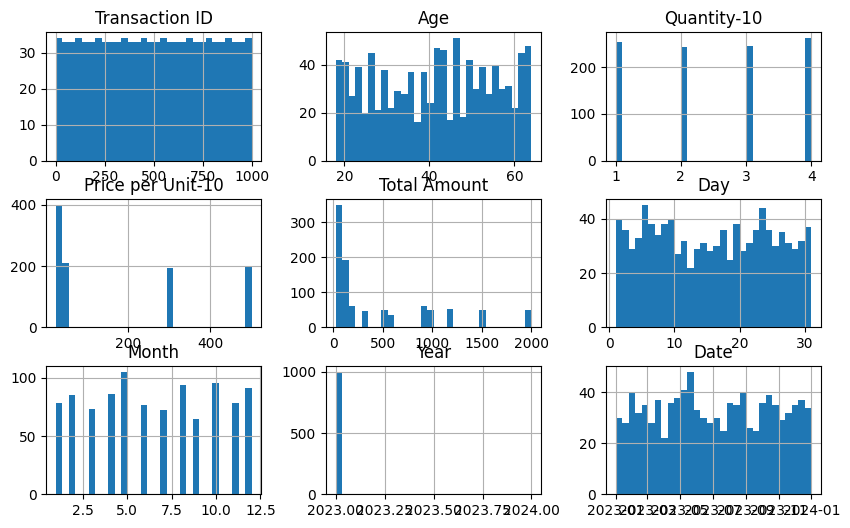

In [ ]:
#الرسمه للداتا الرقميه
data_retail.hist(figsize=(10,6), bins=30)
plt.show()

# Heatmap after clean missing value



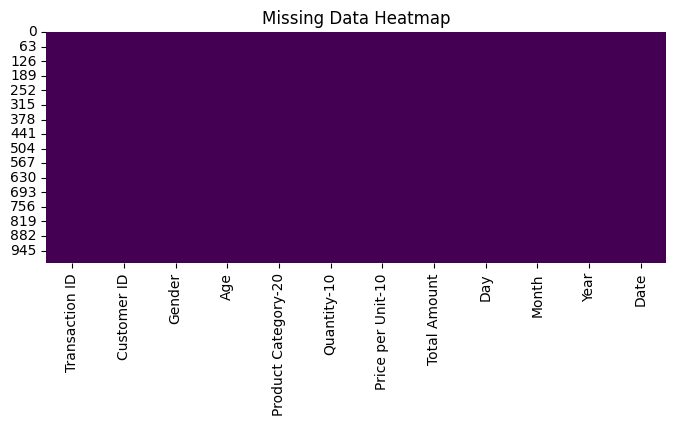

In [ ]:
#  رسمة الهيت وتوضح لنا القيم المفقوده كيف صارت بعد الحذف
plt.figure(figsize=(8,3))
sns.heatmap(data_retail.isnull(), cbar=False, cmap='viridis')
plt.title("Missing Data Heatmap")
plt.show()
#  اللون الاصفر يوضح لنا وين موجودة القيم المفقوده ولاننا حذفناها ف لايظهر اللون الاصفر

# Correlation Heatmap

Scientific Explanation

يُستخدم لقياس قوة العلاقة بين المتغيرات الرقمية.

ليش سويناها ؟ عشان نعرف مين يسيطر , هل العمر يؤثر على المبلغ؟

 Output: تظهر أرقام بين -1 و 1.

 الرقم القريب من 1 (مثل العلاقة بين السعر والإجمالي) يعني "كلما زاد هذا زاد ذاك"

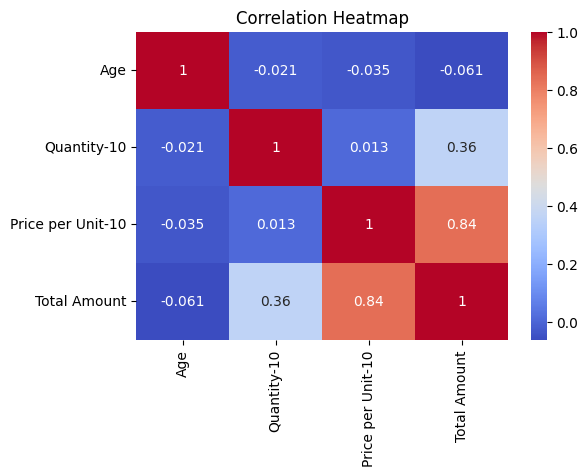

In [ ]:
plt.figure(figsize=(6,4))
sns.heatmap(
    data_retail[['Age', 'Quantity-10', 'Price per Unit-10', 'Total Amount']].corr(),
    annot=True,
    cmap='coolwarm'
)
plt.title('Correlation Heatmap')
plt.show()
# الرسمه توضح price per unit has a strong corr with Total
#and Quntity لها ارتباط متوسط مع Age
# Age ماله تاثير واضح على المبلغ الاجمالي
#لون احمر ةبرتقالي (علاقه قويه)- لون ازرق غامق(مافي علاقه تقريبا)- لون ازرق فاتح (علاقه ضعيفه)
# علاقه قويه :التوتل نع البرايس + البرايس مع التوتل

/tmp/ipykernel_4474/3157789696.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Product Category-20', y='Total Amount', data=category_sales, palette='viridis')


([0, 1, 2],
 [Text(0, 0, 'Beauty'), Text(1, 0, 'Clothing'), Text(2, 0, 'Electronics')])

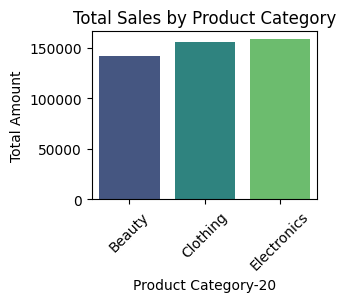

In [ ]:
# ب- Bar Plot: إجمالي المبيعات لكل فئة منتج
category_sales = data_retail.groupby('Product Category-20')['Total Amount'].sum().reset_index()
plt.subplot(2, 2, 2)
sns.barplot(x='Product Category-20', y='Total Amount', data=category_sales, palette='viridis')
plt.title('Total Sales by Product Category')
plt.xticks(rotation=45)

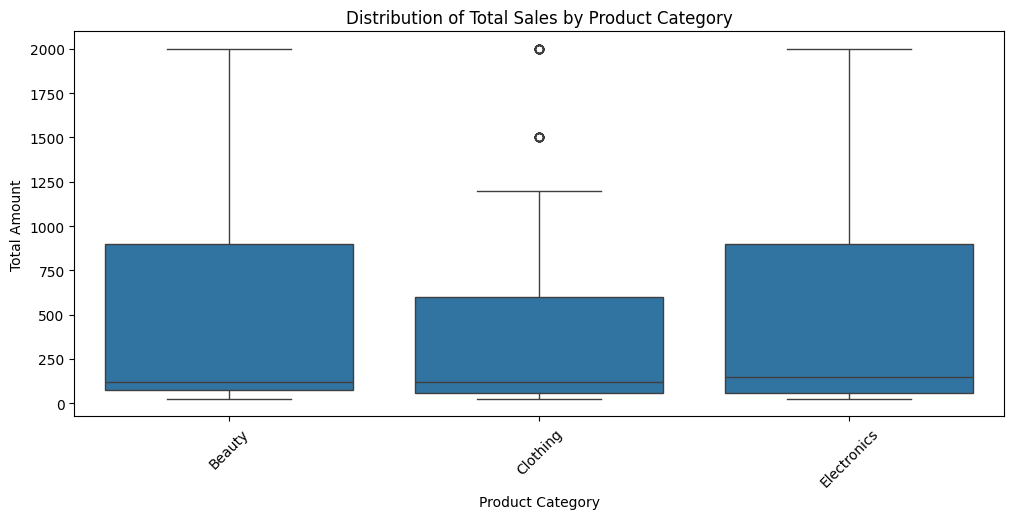

In [ ]:
# توزيع إجمالي المبيعات لكل فئة منتج
# هنا سويت استدعاء لل بلوت و sns ,لانه مايشتغل الكود الا بها
# "هذي الرسمه توضح لنا اجمالي المبيعات لكل فئه منتج "لمعرفة اي فئة منتجات تحقق مبيعات اعلى,واكتشاف الشاذه
plt.figure(figsize=(12,5))
sns.boxplot(x='Product Category-20', y='Total Amount', data=data_retail)
plt.title('Distribution of Total Sales by Product Category')
plt.xlabel('Product Category')# يمدينا نحدد الحجم بس موضروري
plt.ylabel('Total Amount')# يمدينا نحدد الحجم بس مو ضروري
plt.xticks(rotation=45)# اختياريه
plt.show()
# الرسمه توضح ان في قيمتين شاذه عند الملابس

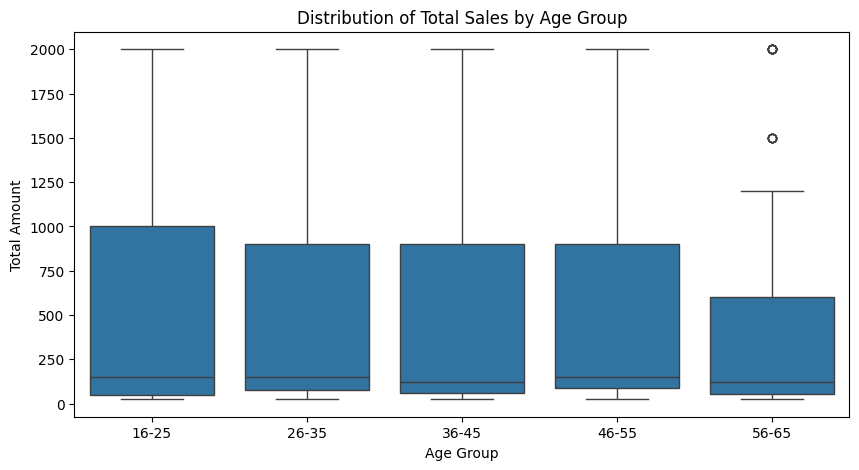

In [ ]:
# استخدمت البوكس بلوت للعمر والتوتل بدال السكتر بلوت
# تقسيم العمر إلى فئات
data_retail['Age Group'] = pd.cut(
    data_retail['Age'],
    bins=[15, 25, 35, 45, 55, 65],
    labels=['16-25', '26-35', '36-45', '46-55', '56-65']
)

plt.figure(figsize=(10,5))
sns.boxplot(x='Age Group', y='Total Amount', data=data_retail)
plt.title('Distribution of Total Sales by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Total Amount')
plt.show()
# الرسم يوضح اجمالي المبيعات لكل فئه عمريه(مقارنة المبيعات بين الفئات العمريه )
# الرسمه توضح في قيمتين شاذه عند الفئه 56-65 (اكتشاف وجود قيم ششاذه)
# كلهم قريبين للمتوسط 1000

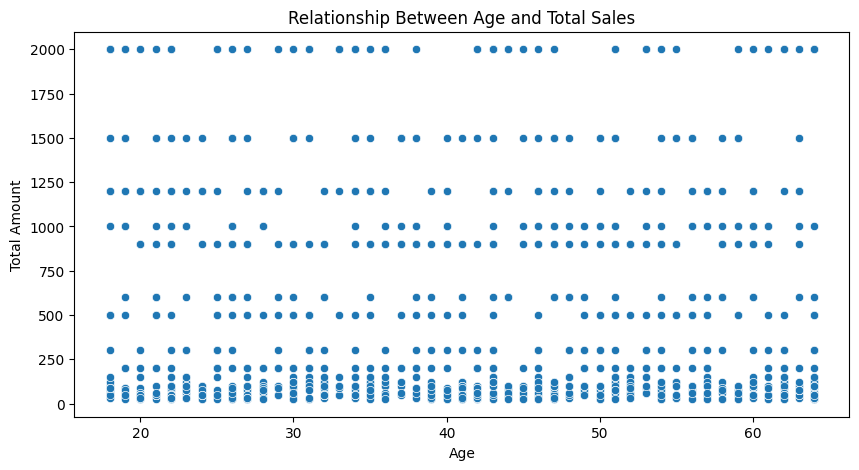

In [ ]:
# العلاقة بين عمر العميل وقيمة المشتريات لاكتشاف اذا كان هناك نمط معين في الشراء حسب العمر
# مثل : هل العملاء الاكبر سنا يشترون اكثر ؟
plt.figure(figsize=(10,5))
sns.scatterplot(x='Age', y='Total Amount', data=data_retail)
plt.title('Relationship Between Age and Total Sales')
plt.xlabel('Age')
plt.ylabel('Total Amount')
#plt.xticks(rotation=90) مو مهم
plt.show()
# استبدلناها بالي فوق افضل
# الرسمه توضح لي مافي علاقه واضحه بين العمر والمبلغ ,القيم موزعه عشوائيه ف العمر لايوثر مباشره على التوتل

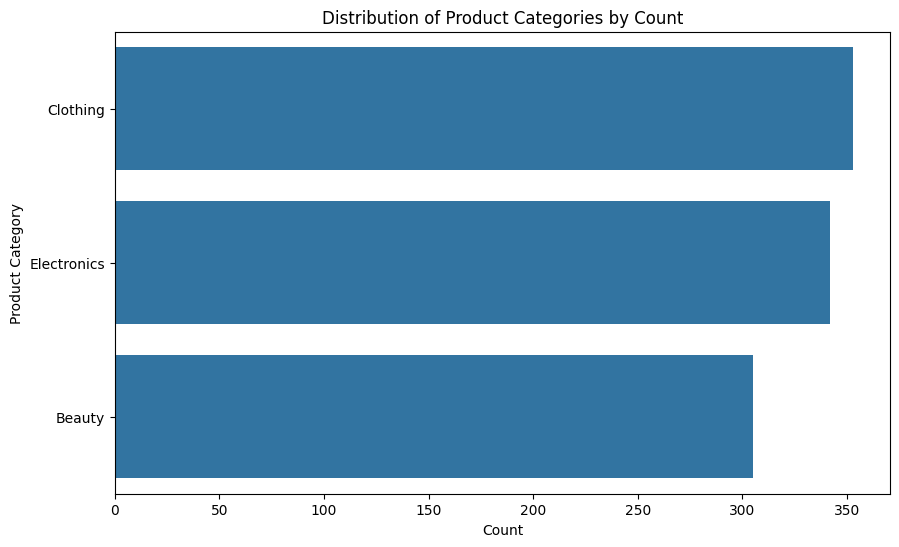

In [ ]:
#  يوضح عدد المعاملات لكل فئة منتج , الهدف لمعرفة اكثر الفئات مبيعا
# الرسم يوضح ويسهل مقارنة التكرار بين الفئات المختلفه
plt.figure(figsize=(10,6))
sns.countplot(
    y='Product Category-20',
    data=data_retail,
    order=data_retail['Product Category-20'].value_counts().index# iloc[:20]هذي كانت بحسب كم تبين شكل يظهر لك بالرسمه بس احنا ماحددنا
)
plt.title('Distribution of Product Categories by Count')
plt.xlabel('Count')
plt.ylabel('Product Category')
plt.show()
# الرسمه توضح لي ان الملابس هي الاكثر تكرار بعدها الاكترونيات والاقل هي الBeaute

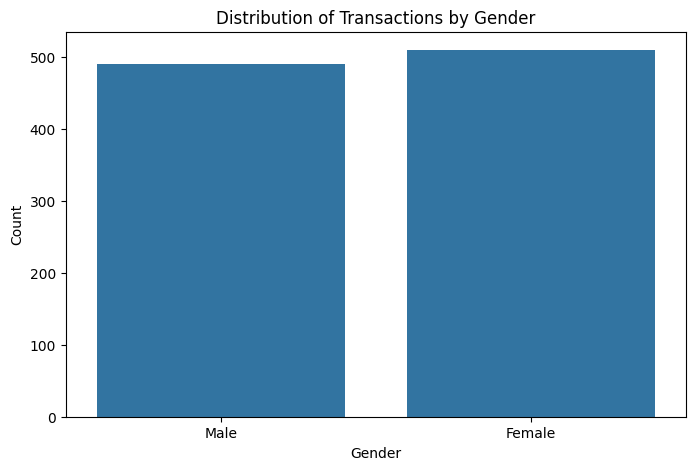

In [ ]:
# يقارن عدد المعاملات بين الذكور والاناث , الهدف لفهم الفروق بين الجنسين في سلوك الشراء
# استخدمنا كونت بلوت مره ثانيه بس لمتغيرات مختلفه
plt.figure(figsize=(8,5))
sns.countplot(x='Gender', data=data_retail)
plt.title('Distribution of Transactions by Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()
#  الرسم يوضح لنا ان الاناث الاكثر شراء

/tmp/ipykernel_4474/256571652.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data_retail["Total Amount"])


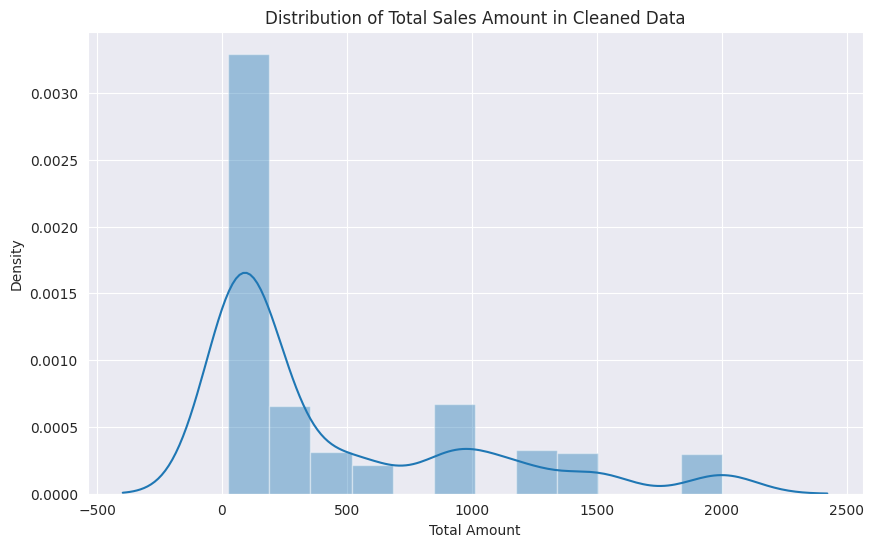

In [ ]:
# يوضح توزيع إجمالي المبيعات
# الخط الكثيف يمثل التةزيع الاحتمالي ,والهدق لمعرفة اذا كانت معظم المبيعات صغيرة او كبيره ف يساعدنا على فهم طبيعة السوق والشراء
plt.figure(figsize=(10,6))
with sns.axes_style('darkgrid'):
    sns.distplot(data_retail["Total Amount"])
plt.title("Distribution of Total Sales Amount in Cleaned Data")
plt.show()
# الرسمه وضحت لنا totalمنخفض وقليل من القيم عالية والتوزيع منحرف يمين ,Rigth-skewed

/tmp/ipykernel_4474/694056978.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data_retail['Quantity-10'])


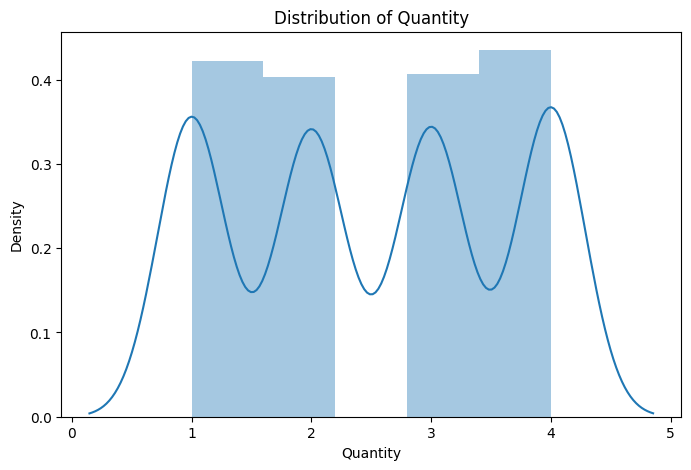

In [ ]:
# قبل الهيت نستخدم رسم توضيحي لل كونتيتي
plt.figure(figsize=(8,5))
sns.distplot(data_retail['Quantity-10'])
plt.title('Distribution of Quantity')
plt.xlabel('Quantity')
plt.ylabel('Density')
plt.show()
#الرسم يوضح التوزيع في المعاملات
#الكميات تقريبا بين 1و2و3و4 ف يعني الارقام منفصله مو متصله عشان كذا الخط المنحنى شكله موج
# اغلب المعاملات كانت بكميه قليله (غالبا1و2)ومافي كميات كبيره يعني واحد اشترى 10 قطع
# التةزيع غير طبيعي (لانه ارقام محدده وصحيحه فقط)

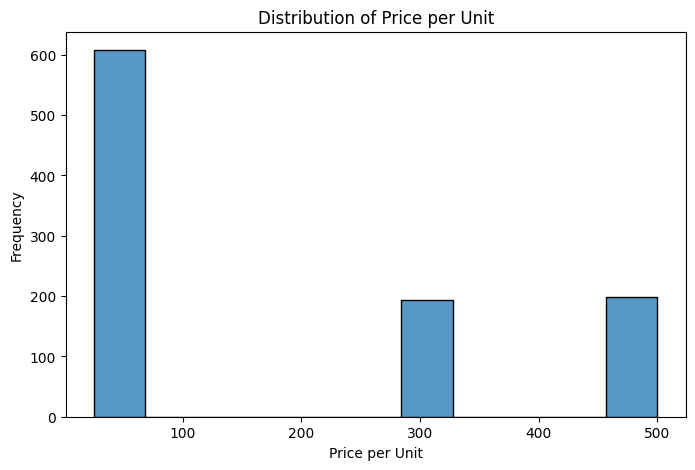

In [ ]:


# قبل الهيت نستخدم رسم توضيحي للتوتل
plt.figure(figsize=(8,5))
sns.histplot(data_retail['Price per Unit-10'], kde=False)
plt.title('Distribution of Price per Unit')
plt.xlabel('Price per Unit')
plt.ylabel('Frequency')
plt.show()
# يوضح لنا الرسمه السعر كم مره تكرر
# نلاحظ من الر مسه مافي قيم عند الفتره 100 وفيه تفاوت بين الباقين
# في تفاوت بالاعمده ف في منتجات غاليه ومنتجات السعر منخفض

#




#  **Section 4: Outliers Detection and Handling**
 فحصنا البيانات للتأكد من خلوها من القيم المتطرفة التي قد تؤثر على النتائج وذلك باستخدام طريقتين
####1: (boxplot)
ستخدمنا هذا الرسم البياني لتمثيل توزيع "إجمالي المبالغ" (Total Amount) بصرياً.

 أي نقطة تظهر خارج "خيوط" الصندوق (Whiskers) تعتبر قيمة شاذة إحصائياً

#### 2: التحليل باستخدام (IQR)
تحديد الحدود: * الحد الأعلى = $Q3 + (1.5 \times IQR)$
##### الحد الأدنى = $Q1 - (1.5 \times IQR)$

### تقنية Removal

تم استخدام تقنية الحذف لاستبعاد القيم غير المنطقية لضمان دقة النتائج وعدم تأثر التحليل بالبيانات الشاذة

In [ ]:
#  حساب حدود IQR
Q1 = data_retail['Total Amount'].quantile(0.25)
Q3 = data_retail['Total Amount'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# تحديد عدد القيم الشاذة
outliers_count = data_retail[(data_retail['Total Amount'] < lower_bound) | (data_retail['Total Amount'] > upper_bound)].shape[0]
print(f"عدد القيم الشاذة المكتشفة: {outliers_count}")


عدد القيم الشاذة المكتشفة: 0


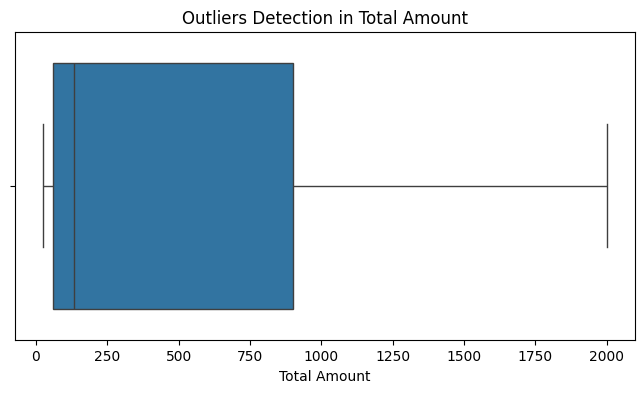

In [ ]:
#  تصور البيانات باستخدام Boxplot لاكتشاف القيم الشاذة
plt.figure(figsize=(8, 4))
sns.boxplot(x=data_retail['Total Amount'])
plt.title('Outliers Detection in Total Amount')
plt.show()
# يووضح الرسم ان المبيعات تتركز عند المبالغ الصغيره (تحت 900)
# الوسيط عند 100 تقريبا

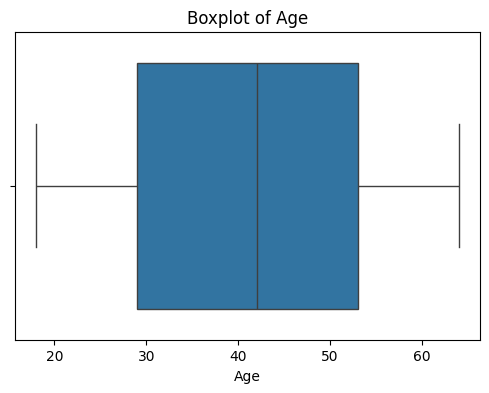

In [ ]:
#Age
plt.figure(figsize=(6,4))
sns.boxplot(x=data_retail['Age'])
plt.title('Boxplot of Age')
plt.show()
#الوسيط عند 42-43 تقريبا
# تقريبا اغلب الاعمار من 28-53
# اصغر عمر 18- اكبر عمر 64
# من الرسمه يوضح انه متوازن

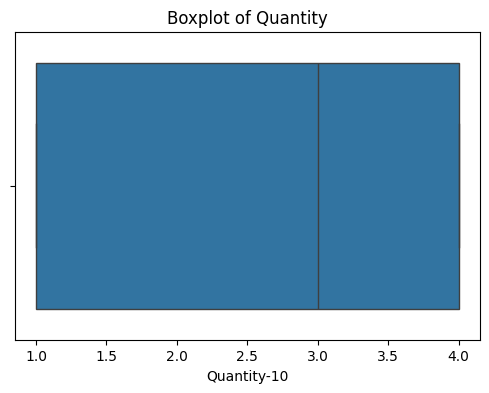

In [ ]:
# Quantity
plt.figure(figsize=(6,4))
sns.boxplot(x=data_retail['Quantity-10'])
plt.title('Boxplot of Quantity')
plt.show()
# الوسيط 3
#الحد الادنيي 1.0-الحد الاعلى 4.0
#ونلاحظ بما ان البوكس كان على كل الحدود ف يعني : ان البيانات هنا محدوده وهي بين 1-2-3-4

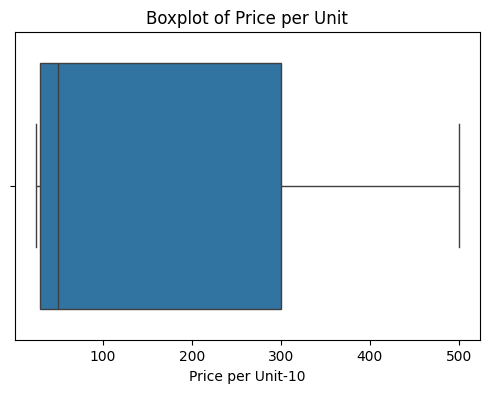

In [ ]:
# Price per Unit
plt.figure(figsize=(6,4))
sns.boxplot(x=data_retail['Price per Unit-10'])
plt.title('Boxplot of Price per Unit')
plt.show()
#الحد الادنى10 -والحد القصى 500
#الوسيط 50
#تقع الاسعار بين 20-300

In [ ]:
# تحسب المدى
Q1 = data_retail['Price per Unit-10'].quantile(0.25)
Q3 = data_retail['Price per Unit-10'].quantile(0.75)
#يحسب لنا المسافه بينهم و يمثل منتصف البيانات بدون الاطراف
IQR = Q3 - Q1
# تحسب الحدود(اذا طلعت القيمه اقل من الصغير او اكبر من الكبير ف تعتبر شاذه )
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Lower Bound:", lower)
print("Upper Bound:", upper)
# من الاوت بوت وضح لنا حدود البيانات

Lower Bound: -375.0
Upper Bound: 705.0


لماذا اخترنا Log Transformation

  يكون في مبيعات بـ 10 ريال ومبيعات بـ 5000 ريال. الفجوة كبيرة اللوغاريتم يضغط هذه الفجوة لتصبح البيانات قريبه من بعض وقابلة للمقارنة.  

ماذا يحدث في  Output

 رسمتين (Before & After). قبل التحويل يكون الرسم "منحرفاً"، وبعده يصبح "متماثلاً" كالجرس (Normal Distribution).

In [ ]:
# Apply Log Transformation
data_retail['Log_Price_per_Unit'] = np.log1p(data_retail['Price per Unit-10'])
data_retail['Log_Total_Amount'] = np.log1p(data_retail['Total Amount'])
#يساعد ال log ,ان القيم الكبيره تنضغط (تقل) ف الفجوه بينهم تقل وتقلل الانحراف
#استخدمنا log1p عشان لو فيه اصفار يقدر يتعامل معاها

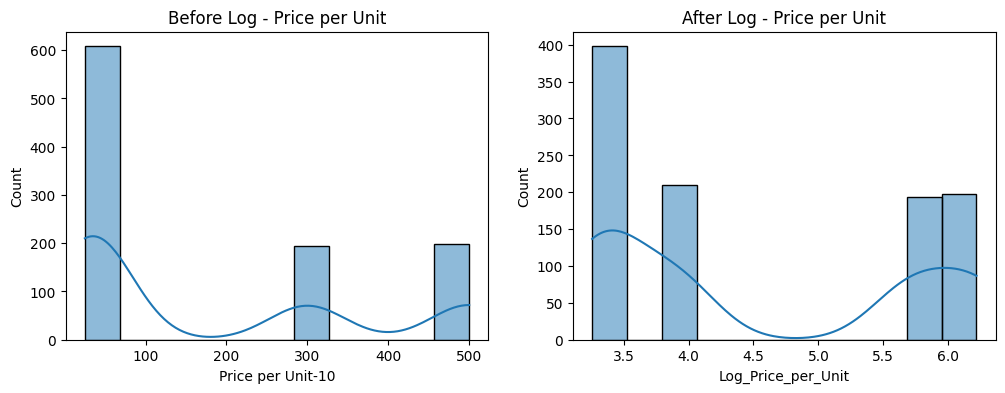

In [ ]:
# يرسم هيستغرام على محور X-القيم
# على محور Y-التكرار
# ال Kde هو الخط المرسوم على الاعمده
plt.figure(figsize=(12,4))
# استخدمنا سب بلوت اثنين عشان توضح جنب بعض
plt.subplot(1,2,1)
sns.histplot(data_retail['Price per Unit-10'], kde=True)
plt.title('Before Log - Price per Unit')

plt.subplot(1,2,2)
sns.histplot(data_retail['Log_Price_per_Unit'], kde=True)
plt.title('After Log - Price per Unit')

plt.show()
# من خلال الرسمه وضحت لنا : الفجوه بينهم انخفضت
#الاعداد على محور X-  صارت اقرب واقل بين (0-400)
# الاعداد على محور Y- جدا صغيره بين (3.5-6)

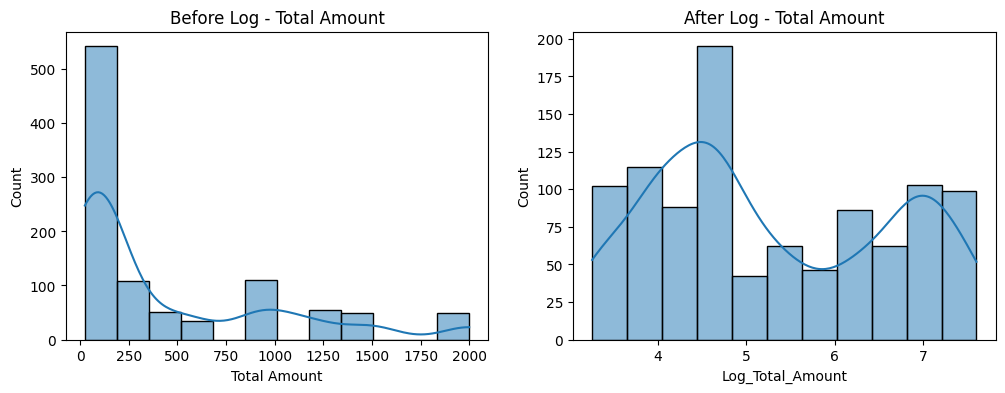

In [ ]:
# يرسم هيستغرام على محور X-القيم
# على محور Y-التكرار
# ال Kde هو الخط المرسوم على الاعمده
plt.figure(figsize=(12,4))
# استخدمنا سب بلوت اثنين عشان توضح جنب بعض
plt.subplot(1,2,1)
sns.histplot(data_retail['Total Amount'], kde=True)
plt.title('Before Log - Total Amount')

plt.subplot(1,2,2)
sns.histplot(data_retail['Log_Total_Amount'], kde=True)
plt.title('After Log - Total Amount')

plt.show()
# من خلال الرسمه وضحت لنا : الفجوه بينهم قلة وتقاربت الاعمده
# غلى محور اكس صارت اقل وبين (0-200)
# على محور Y- جدا قلة الارقام وضارت صغيره بين (0-8تقريبا )

# Section 5: (Data Transformation)
MinMaxScaler (Scaling) لتوحيد نطاق القيم الرقمية، وهو ضروري لأن الخوارزميات تتأثر باختلاف المقاييس بين الأعمدة. وتم استخدام Label Encoding لتحويل البيانات النصية إلى أرقام لأن النماذج البرمجية لا يمكنها معالجة النصوص مباشرة

# 1.Normalization (Min-Max Scaling)
Min-max scaling, also known as rescaling, is a popular normalization technique that rescales the data to a common range, usually between 0 and 1. This is achieved by subtracting the minimum value and then dividing by the range of the data.

X scaled = X -Xmin / Хтах-Xmin
Where:

(x) = original value

(Xmin) = minimum value in the feature

(Xmaz) = maximum value in the feature

(Xscaled) in [0,1] -> the new scaled value, which will lie between 0 and 1


الطريقة المختارة:


تم اختيار Min-Max Scaling كأفضل طريقة لمعالجة البيانات
 العددية في هذا اللاب،

 لأنها مناسبة للبيانات التي لا تحتوي على Outliers

وتقوم بتوحيد مقياس القيم بين 0 و 1 .


In [ ]:
#Min-Max Scaling (Quantity)

scaler = MinMaxScaler()

data_retail[['Quantity_minmax']] = scaler.fit_transform(data_retail[['Quantity-10']])
# عرض قبل وبعد
data_retail[['Quantity-10', 'Quantity_minmax']].head()
# يخلي القيم بين صفر و واحد
# حساس للاوتليرز
# اخترنا ال Quantity لانه ال انج حقه صغير  وعدد مبيعات
# نبغى نحوله لقيم بين صفر و واحد عشان لو دخلناه في مودل مايتاثر بحجمه

,Quantity-10,Quantity_minmax
0,3.0,0.666667
1,2.0,0.333333
2,1.0,0.000000
3,1.0,0.000000
4,2.0,0.333333


#  Label Encoding
Gender تم استخدامه على عامود

في هذه الطريقة يتم تحويل القيم النصية إلى أرقام

لان لانستطيع التعامل مع النصوص مباشره وهذا العامود يحتوي على فئتين فقط

In [ ]:
# Label Encoding (Gender)

encoder = LabelEncoder()

data_retail['Gender_label'] = encoder.fit_transform(data_retail['Gender'])
# عرض قبل وبعد
data_retail[['Gender_label', 'Gender']].head()

# اخترنا الCender لانه فئة بسيطه (Male-famel)
#نحوله لارقام عشان المودل يفهمه
#لو المتغير اسمي (Nominal) فـ Label Encoding مو الأفضل

,Gender_label,Gender
0,1,Male
1,0,Female
2,1,Male
3,1,Male
4,1,Male


In [ ]:
#  تحويل البيانات الفئوية (النصوص) إلى أرقام
le = LabelEncoder()
data_retail['Gender'] = le.fit_transform(data_retail['Gender'])
data_retail['Product Category-20'] = le.fit_transform(data_retail['Product Category-20'])

#  توحيد مقاسات البيانات الرقمية (بين 0 و 1)
scaler = MinMaxScaler()
numerical_cols = ['Age', 'Quantity-10', 'Price per Unit-10', 'Total Amount']
data_retail[numerical_cols] = scaler.fit_transform(data_retail[numerical_cols])

# عرض شكل البيانات والجدول النهائي
print("Dataset shape after transformation:")
print(data_retail.shape)
data_retail.head()

Dataset shape after transformation:
(1000, 15)


,Transaction ID,Customer ID,Gender,Age,Product Category-20,Quantity-10,Price per Unit-10,Total Amount,Day,Month,Year,Date,Age Group,Log_Price_per_Unit,Log_Total_Amount
0,1,CUST001,1,0.347826,0,0.666667,0.052632,0.063291,24,11,2023,2023-11-24,26-35,3.931826,5.017280
1,2,CUST002,0,0.173913,1,0.333333,1.000000,0.493671,27,2,2023,2023-02-27,26-35,6.216606,6.908755
2,3,CUST003,1,0.695652,2,0.000000,0.010526,0.002532,13,1,2023,2023-01-13,46-55,3.433987,3.433987
3,4,CUST004,1,0.413043,1,0.000000,1.000000,0.240506,21,5,2023,2023-05-21,36-45,6.216606,6.216606
4,5,CUST005,1,0.260870,0,0.333333,0.052632,0.037975,6,5,2023,2023-05-06,26-35,3.931826,4.615121


# Section 6: Feature Engineering
### Feature Creation (Average_Price)
تم إنشاء ميزة "Average_Price" لربط السعر بالكمية، مما يساعد في تحديد نمط الإنفاق الفردي لكل عميل بدقة أكبر من الاعتماد على السعر الإجمالي فقط.

### Feature Selection
تم اختيار الأعمدة السلوكية مثل (Age, Gender, Category, Quantity) واستبعاد الأعمدة التعريفية (Transaction ID, Customer ID) لأنها مجرد أرقام تسلسلية لا تضيف أي قيمة تحليلية وتسبب ضجيجاً للنموذج

### Feature Extraction (PCA)
استخدمنا تقنية PCA لتقليل أبعاد البيانات (Dimensionality Reduction) ودمج الميزات المترابطة، مما يقلل من تعقيد البيانات ويسرع عملية المعالجة مع الحفاظ على أهم المعلومات الأساسية

###Recursive Feature Elimination (RFE)

اختيار أهم  ميزات تؤثر على Total Amount.

يساعد على تبسيط النماذج وتحسين الأداء.

In [ ]:
#  حذف الأسطر اللي فيها الكمية صفر عشان ما يطلع "مالانهاية" عند القسمة
data_retail = data_retail[data_retail['Quantity-10'] != 0]

#  حساب متوسط السعر وتنظيف أي فراغات
data_retail['Average_Price'] = data_retail['Total Amount'] / data_retail['Quantity-10']
# استخدمنا دروب بعد عملية القسمه لاستبدال اي قيمه خاطئه ب NaN
data_retail = data_retail.replace([np.inf, -np.inf], np.nan).dropna()

# اختيار الأعمدة وتطبيق الـ PCA
features = data_retail[['Age', 'Gender', 'Product Category-20', 'Quantity-10', 'Price per Unit-10', 'Average_Price']]
# يختار الاعمده الاكثر تاثيراويضغطها في مكونين فقط PC1-PC2
pca = PCA(n_components=2)
pca_results = pca.fit_transform(features)

# عرض النتائج
print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)
# الاوت يوضح المعلومات التي استطاع PCA الاحتفاظ بها بعد الضغط
#وهي الاول 44 والثاني 26 ف معا يغطون جزء كبير

Explained Variance Ratio:
[0.44757161 0.26266487]


In [ ]:
# Feature Selection using RFE

X = data_retail[['Age','Gender','Product Category-20','Quantity-10','Price per Unit-10','Average_Price']] #المدخلات
y = data_retail['Total Amount'] # الهدف
# استخدمنا الانحدار الخطي اداة للقياس
model = LinearRegression()
# يختار افضل 5 متغيرات
rfe = RFE(model, n_features_to_select=5)
X_selected = rfe.fit_transform(X, y)
rfe.support_
# الاوت يوضح : ترو للمختار و فولز للمستبعد
# البرودكن كاتبغوري هي الوحيده المسبعده لانه ماياثر على التوتل

array([ True,  True, False,  True,  True,  True])

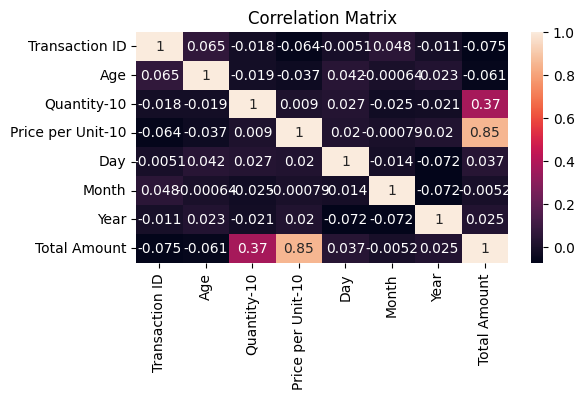

In [ ]:
# Correlation (Heatmap)

# Create a copy of X and add the target variable 'Total Amount'
corr = X.copy()
corr['Total Amount'] = y
#هنا عشان الاعمده لازم رقميه

# Select only numerical columns before calculating correlation
# This ensures that string columns like 'Customer ID' do not cause a ValueError
# هذي عشان نشوف اي عامود ياثر على التارغت
#البرايس مان هو اكثر تاثير من خلال الرقم
numeric_corr = corr.select_dtypes(include=np.number)

plt.figure(figsize=(6,3))
sns.heatmap(numeric_corr.corr(), annot=True)
plt.title("Correlation Matrix")
plt.show()

In [ ]:
# PCA
# بعد اختيار الافضل اعمده هنا يضغطها لتسهيل التحليل ورسمها
pca = PCA(n_components=2)# تكون في محورين فقط
pca_results = pca.fit_transform(X_selected)# هنا ضغط البيانات
#هذي النتيجه وتورينا مدى نجاح الضغط
pca.explained_variance_ratio_
# الاوت يوضح المكون اللول ضغط47.5 والمكون الثاني ضغط 31 والمجموه 78 ممتاز

array([0.47529217, 0.31080959])

##Section 7 – Analysis & Results / Insights

استخراج اليوم والشهر من عمود التاريخ.

مهم لتحليل الأنماط الموسمية واليومية في المبيعات.

groupby('Month')  تجميع المبيعات لكل شهر.
يعطي صورة واضحة لأي شهر تكون فيه المبيعات أعلى.

رسمة الشهور: تظهر أعمدة متفاوتة. الطويل منها يعني "موسم ربح" (Peak Season)

تحليل الأنماط اليومية خلال الشهر.
يساعد على معرفة أيام الذروة والأيام الهادئة.

تظهر رسمة "نقاط مبعثرة" (Scatter Plot).    

النقاط
متجمعة في مجموعات ملونة،فهذا يعني أن البرنامج استطاع التمييز بين أنواع الزبائن تلقائياً.

Insights حسب الفئه والجنس والفئه العمريه



In [ ]:
# Extract Day and Month from Date
data_retail['Day'] = data_retail['Date'].dt.day
data_retail['Month'] = data_retail['Date'].dt.month

هذا الرسم يوضح أداء المبيعات على مدار أشهر السنة؛ الهدف منه تحديد مواسم الذروة (High Season) عشان نجهز لها المخزون، ونفهم متى ينخفض الطلب عشان نعدل خططنا التسويقية

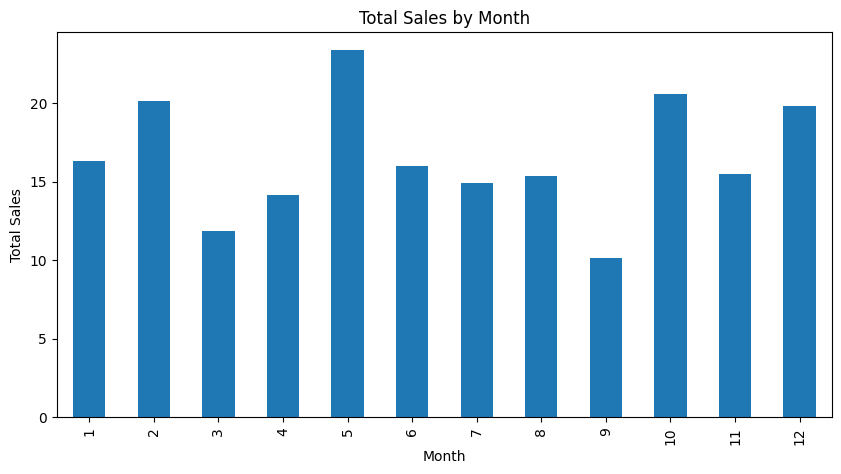

In [ ]:
# Sales by Month
monthly_sales = data_retail.groupby('Month')['Total Amount'].sum()
monthly_sales.plot(kind='bar', figsize=(10,5))
plt.title('Total Sales by Month')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.show()

اخترت الرسم يكون "خطي" (Line Chart)؛ وهذا أفضل نوع هذا الرسم يوضح تذبذب المبيعات خلال أيام الشهر؛ الهدف منه معرفة أيام الذروة لتكثيف الموظفين، ومعرفة الأيام الضعيفة لعمل عروض منتصف الشهر تزيد اقبال  الزبائن

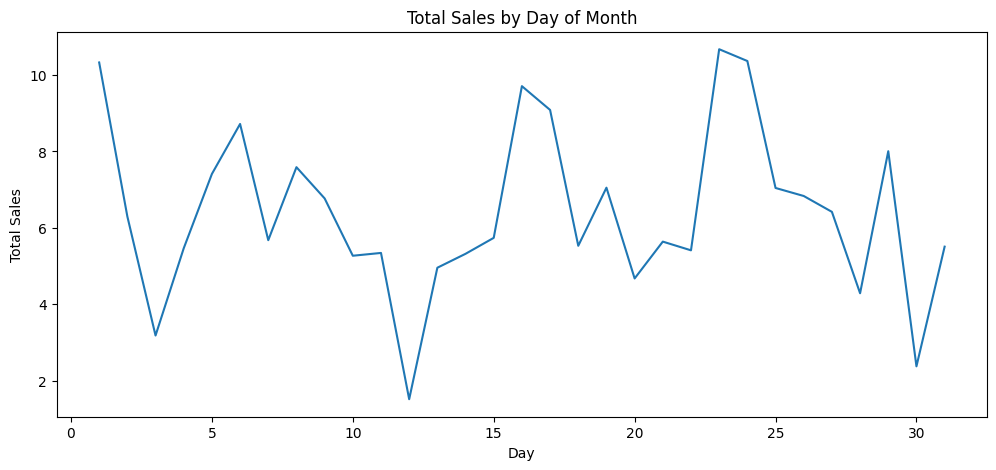

In [ ]:
#  Sales by Day
daily_sales = data_retail.groupby('Day')['Total Amount'].sum()
daily_sales.plot(kind='line', figsize=(12,5))
plt.title('Total Sales by Day of Month')
plt.xlabel('Day')
plt.ylabel('Total Sales')
plt.show()

هذا الرسم يمثل خلاصة ضغط أبعاد البيانات في بُعدين فقط؛ استخدمته لتوضيح كيف تتجمع فئات المنتجات بناءً على تشابه سلوك الزبائن، مما يساعدنا في فهم الأنماط الخفية التي لا تظهر في الجداول التقليدية

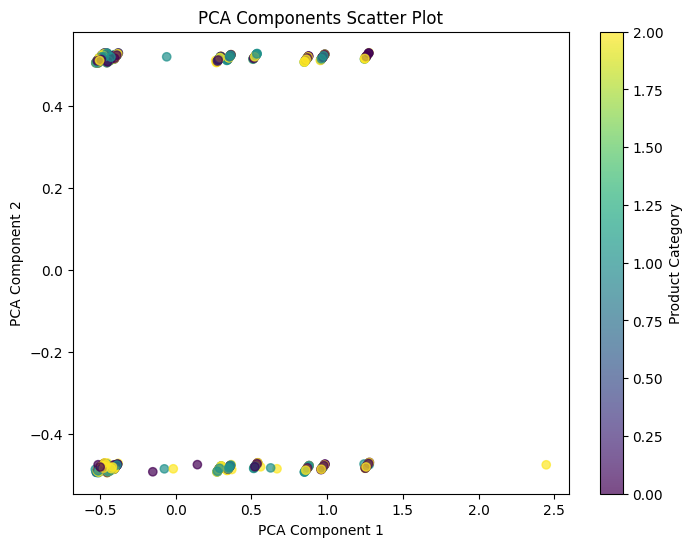

In [ ]:
# PCA Components Scatter Plot
# توزيع البيانات بعد تقليل الابعاد ونشوف تجمعات الفئه المختلفه
plt.figure(figsize=(8,6))
plt.scatter(pca_results[:,0], pca_results[:,1], c=data_retail['Product Category-20'], cmap='viridis', alpha=0.7)
plt.title('PCA Components Scatter Plot')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.colorbar(label='Product Category')
plt.show()
#انقسام البيانات فوق وتحت عند 0.5 و -0.5
#كلما اتجهت النقاط يمين زادت قيمتها في المكون الاول
# بما ان PCA يجمع بين السعر والكميه فالنقاط الموجوده في اقصى اليمين تمثل عمليات الشراء الضخمه واليسار العاديه
#

In [ ]:
# Insights by Product Category
#يعرض أعلى 3 فئات مبيعًا.
top_categories = data_retail.groupby('Product Category-20')['Total Amount'].sum().sort_values(ascending=False).head(3)
top_categories

,Total Amount
Product Category-20,
2,68.567089
1,66.627848
0,62.969620


In [ ]:
# Insights by Gender
#يساعد على معرفة أي جنس يساهم أكثر في المبيعات.
gender_sales = data_retail.groupby('Gender')['Total Amount'].sum()
gender_sales

,Total Amount
Gender,
0,101.177215
1,96.987342


In [ ]:
# Insights by Age Group
#يساعد على فهم العملاء الأكثر مساهمة في الإيرادات.
age_sales = data_retail.groupby('Age Group')['Total Amount'].sum()
age_sales

/tmp/ipykernel_4474/1093843082.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_sales = data_retail.groupby('Age Group')['Total Amount'].sum()


,Total Amount
Age Group,
16-25,37.278481
26-35,43.032911
36-45,40.440506
46-55,43.002532
56-65,34.410127
